# The shipped models re-scored with the official metric

**The question:** the models were chosen on per-run TIMSE / persistence. On 2026-10-25 the organisers
released the official metric (`docs/timse_implementation.pdf`, `training.competition_score`): per lead,
S_τ = √(RMSE_τ · √TIMSE_τ) with a 100-percentile, range-normalised TIMSE, averaged over the 72 leads,
against SWPC's hourly ACE file (status ≠ 0 missing). Do the model choices still hold?

**The test** (`python -m training.official_rescore`): the final baseline, the linear model and the hybrid,
fitted as in `training.compare_history`, plus the spec's baselines, on the six yearly folds
(2019-10 → 2025-10). Truths: the official file, the same file with every status, and the training
series. Nothing is re-tuned. The eval year is not used.

1. The official truth against the training truth
2. Scores
3. By fold
4. Lead curves
5. Bias
6. Findings

## 1. The official truth against the training truth

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import official_rescore as orx
from training import pull_ace_1h
from training.datasets import DATA_START, EVAL_END, load_hourly

official = pull_ace_1h.load()
train = load_hourly()
idx = train.index[(train.index >= DATA_START) & (train.index < EVAL_END)]
a, b = train.reindex(idx), official.reindex(idx)
both = a.notna() & b.notna()
d = (b - a)[both]
print(f"valid hours: training {a.notna().mean():.1%}, official {b.notna().mean():.1%}; "
      f"official - training where both: median |d| {d.abs().median():.2f} km/s, "
      f"{(d.abs() < 5).mean():.1%} within 5 km/s")
display(pd.DataFrame({"training": a.notna(), "official": b.notna()})
        .groupby(idx.year).mean().T.round(3))

rows = []
for path in sorted(pull_ace_1h.RAW_DIR.glob("*.txt")):
    for line in path.read_text(encoding="ascii").splitlines():
        if line[:1].isdigit():
            p = line.split()
            stamp = f"{p[0]}-{p[1]}-{p[2]}T{p[3][:2]}:{p[3][2:]}Z"
            rows.append((stamp, int(p[6]), float(p[8])))
status = pd.DataFrame(rows, columns=["time", "status", "speed"])
status = status.drop_duplicates("time", keep="last")
status["time"] = pd.to_datetime(status["time"], utc=True)
status = status.set_index("time").loc[idx[0]:idx[-1]]
status["training speed"] = a.reindex(status.index)
display(status.groupby("status").agg(
    share=("speed", lambda s: len(s) / len(status)),
    training_has_speed=("training speed", lambda s: s.notna().mean()),
    mean_training_speed=("training speed", "mean")).round(3))

valid hours: training 91.1%, official 70.4%; official - training where both: median |d| 0.25 km/s, 94.4% within 5 km/s


Time,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
training,0.668,0.759,0.836,0.954,0.922,0.926,0.911,0.929,0.962,0.986,0.992
official,0.563,0.642,0.717,0.825,0.738,0.781,0.641,0.655,0.690,0.680,0.695


,share,training_has_speed,mean_training_speed
status,,,
0,0.705,0.998,423.399
1,0.099,0.990,451.788
3,0.020,0.965,424.591
4,0.000,1.000,443.668
6,0.005,0.914,428.122
9,0.171,0.501,436.282


## 2. Scores (official truth; S in km/s, '/ persistence' is the geometric mean over folds)

In [2]:
df = pd.read_csv(orx.EXPERIMENTS / "official_rescore.csv").set_index("fold")
names = (*orx.MODELS, *orx.BASELINES)


def table(truth):
    ref = df[f"{truth} | persistence | s_final"]
    out = {}
    for n in names:
        s = df[f"{truth} | {n} | s_final"]
        out[n] = {"S_final": s.mean(), "/ persistence": float(np.exp(np.log(s / ref).mean())),
                  **{k: df[f"{truth} | {n} | {k}"].mean()
                     for k in ("rmse", "trmse", "bias", "s_49_72")}}
    return pd.DataFrame(out).T.sort_values("S_final")


with pd.option_context("display.float_format", "{:.3f}".format):
    display(table("official"))
    display(pd.DataFrame({t: table(t)["/ persistence"] for t in orx.TRUTHS}))

,S_final,/ persistence,rmse,trmse,bias,s_49_72
linear,93.695,0.842,85.848,104.334,56.122,115.571
hybrid,94.002,0.843,87.094,102.902,57.255,114.534
final baseline,99.818,0.899,85.717,118.695,52.499,121.907
persistence (t0),109.010,0.985,78.486,152.949,1.808,143.325
persistence,110.571,1.000,79.700,154.917,1.886,143.900
recurrence 27 d,129.039,1.163,95.569,176.703,-0.786,138.307
climatology,138.583,1.249,90.743,214.350,-6.068,138.607


,official,any status,training
linear,0.842,0.840,0.841
hybrid,0.843,0.840,0.842
final baseline,0.899,0.897,0.900
persistence (t0),0.985,0.986,0.986
persistence,1.000,1.000,1.000
recurrence 27 d,1.163,1.171,1.187
climatology,1.249,1.247,1.248


## 3. By fold: official S_final, and hybrid vs linear on both metrics

In [3]:
s = pd.DataFrame({n: df[f"official | {n} | s_final"] for n in names})
display(s.round(1))
pairs = pd.DataFrame({
    "official: hybrid / linear - 1": s["hybrid"] / s["linear"] - 1,
    "old metric: hybrid / linear - 1": df["hybrid | old ratio"] / df["linear | old ratio"] - 1})
display((100 * pairs).round(2))

,final baseline,linear,hybrid,persistence,persistence (t0),recurrence 27 d,climatology
fold,,,,,,,
2019-10,76.1,70.0,68.0,83.3,81.8,95.0,109.6
2020-10,79.5,74.5,73.6,99.6,97.3,105.1,106.8
2021-10,95.4,86.2,88.5,105.0,103.4,134.7,128.9
2022-10,101.6,95.1,95.9,104.4,103.5,133.0,145.4
2023-10,133.7,124.5,123.8,133.8,132.7,171.0,157.4
2024-10,112.6,111.8,114.2,137.3,135.3,135.5,183.3


,official: hybrid / linear - 1,old metric: hybrid / linear - 1
fold,,
2019-10,-2.89,-4.70
2020-10,-1.20,-0.18
2021-10,2.63,-2.15
2022-10,0.82,-1.41
2023-10,-0.60,-0.34
2024-10,2.20,-0.40


## 4. Lead curves (mean over folds, official truth)

,linear,hybrid,final baseline,persistence
1,23.3,27.7,23.4,25.1
6,48.1,51.0,49.9,50.6
12,67.0,69.0,72.1,71.0
24,91.3,91.9,99.3,101.1
48,111.2,110.7,119.3,136.8
72,124.6,123.2,130.5,151.6


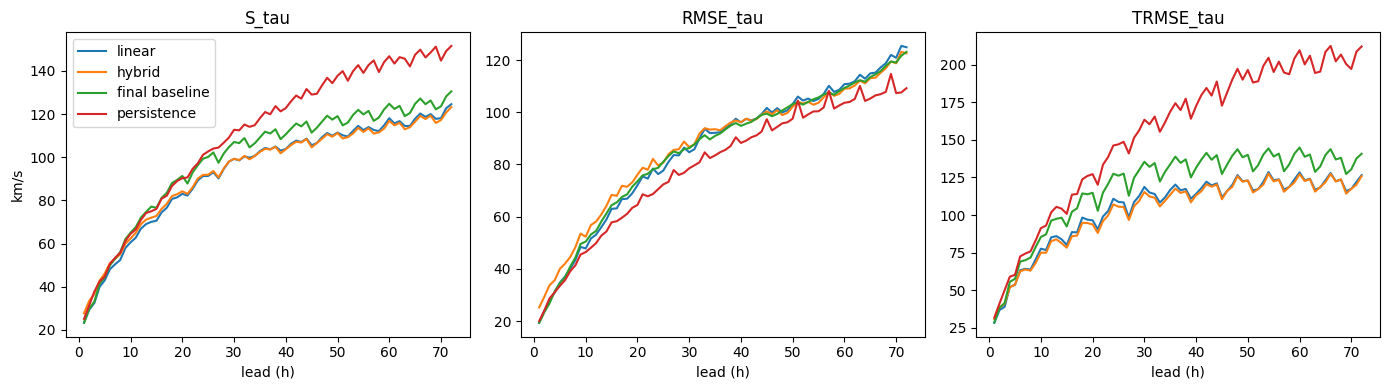

In [4]:
curves = json.loads((orx.EXPERIMENTS / "official_rescore_curves.json").read_text())
show = ("linear", "hybrid", "final baseline", "persistence")


def mean_curve(name, key):
    return np.mean([curves[f][name][key] for f in curves], axis=0)


lead = np.arange(1, 73)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, key, title in zip(axes, ("s", "rmse", "trmse"), ("S_tau", "RMSE_tau", "TRMSE_tau"),
                          strict=True):
    for n in show:
        ax.plot(lead, mean_curve(n, key), label=n)
    ax.set_title(title)
    ax.set_xlabel("lead (h)")
axes[0].set_ylabel("km/s")
axes[0].legend()
plt.tight_layout()
display(pd.DataFrame({n: mean_curve(n, "s")[[0, 5, 11, 23, 47, 71]] for n in show},
                     index=[1, 6, 12, 24, 48, 72]).round(1))

## 5. Bias by lead (forecast − observation, mean over folds)

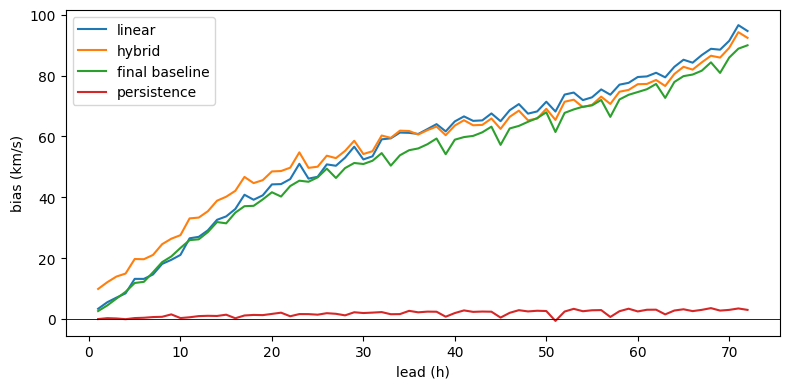

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for n in show:
    ax.plot(lead, mean_curve(n, "bias"), label=n)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lead (h)")
ax.set_ylabel("bias (km/s)")
ax.legend()
plt.tight_layout()

## 6. Findings

- **The hybrid's edge is gone.** On the official metric it is 0.14% worse than the linear model (3 of 6 folds); on the old metric it was 1.5% better. It is clearly worse at short leads (section 4) and slightly better at long ones.
- **Both still beat the final baseline** by about 6%, and persistence by about 16%.
- **Bias is the largest problem** (section 5). Every model over-forecasts, by +3 km/s at 1 h rising to +90–95 km/s at 72 h: the old metric's TIMSE weights made that optimal. The official metric counts RMSE as much as the tail, and on RMSE every model is worse than persistence.
- **The truth doesn't change the picture.** The official file drops 30% of hours: status 9 "no data" and status 1 "bad". But scoring against every non-fill speed, or against the training truth, gives the same order within 0.5%.

**Next:** re-tune for the official metric, with a per-lead bias correction and training weights that match it, on these folds. See `docs/official_score.md`.